# Velocity — figures

The figure of Supplementary Note 2, made **only from saved results**
(`results/velocity.npz`, written by `s02a_velocity_fit`): numpy and matplotlib,
no `curlew` or `torch`. Writes `figures/figS_velocity`.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, to_rgb
from matplotlib.lines import Line2D

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import figstyle
import diagnostics
figstyle.apply()

RES_DIR = Path("./results")
FIG_DIR = Path("./figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Load

In [2]:
res = np.load(RES_DIR / "velocity.npz")
VARIANTS = [str(v) for v in res["variants"]]
V_LABEL = {"euler": "solenoidal", "free": "unconstrained"}   # "euler" is the key in the results
V_COLOR = {"euler": figstyle.HORIZON_PALETTE[0], "free": figstyle.HORIZON_PALETTE[4]}
x, z = res["x"], res["z"]
contacts = diagnostics.unpack_contacts(res, len(VARIANTS), 2)
truth = np.load("../01_recumbent_fold/data/synthetic/truth.npz")
origin = np.load("../01_recumbent_fold/results/synthetic/inputs.npz")["origin"]
truth_contacts = [truth[f"contact_{name}"] - origin for name in ("rock2", "rock1")]   # H0, H1
H_COLORS = [figstyle.HORIZON_PALETTE[0], figstyle.HORIZON_PALETTE[1]]
HALF = 600.0
OUTSIDE_GREY = "0.86"


def get(v, key):
    return res[f"{v}_{key}"]


# Fits that did not fit the data are left out of every comparison, with their pair.
FIT_LOSS = 1e-2
ok = np.logical_and.reduce([get(v, "loss")[:, -1] < FIT_LOSS for v in VARIANTS])
for v in VARIANTS:
    for k in np.nonzero(get(v, "loss")[:, -1] >= FIT_LOSS)[0]:
        print(f"left out: {v} on seed {res['seeds'][k]} (final loss {get(v, 'loss')[k, -1]:.2g})")
print(f"paired comparisons on {ok.sum()} of {len(ok)} bases")


def tint(color, f):
    return tuple(1.0 - f * (1.0 - np.asarray(to_rgb(color))))

paired comparisons on 5 of 5 bases


## Fig. S4: the two velocities

**a, b** Restored elevation $\psi_p$ of the main-text seed, one colour scale,
isolines every 50 m, with the fitted contacts over the true ones (dashed).
**c, d** $\ln J$, each on its own scale: for the solenoidal velocity it is the
error of RK4 alone. **e** Strain energy per basis. **f** How far $J$ departs from
one per basis, on a log axis: the larger of $|\ln J|$ at the 5th and 95th
percentiles. **g** The largest $\lVert\mathbf D\tilde{\boldsymbol\varphi}_h-\mathbf I\rVert_2$ of one RK4
step per basis; below 1 (dashed) every step is injective. **h** Loss against
iteration, median and interquartile range; dotted, `FIT_LOSS`.

solenoidal: |ln J| at most 2.58e-04 on the grid (main-text seed)
unconstrained: |ln J| at most 2.66e+00 on the grid (main-text seed)


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


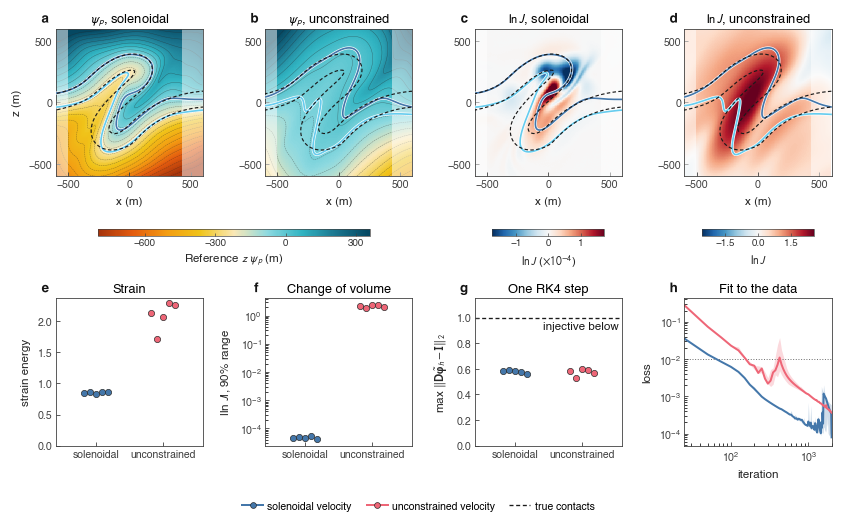

In [3]:
def frame(ax, *, ylabel=False):
    ax.set_xlim(-HALF, HALF)
    ax.set_ylim(-HALF, HALF)
    ax.set_aspect("equal")
    ax.set_xticks([-500, 0, 500])
    ax.set_yticks([-500, 0, 500])
    ax.set_xlabel("x (m)")
    ax.set_ylabel("z (m)" if ylabel else "")


def draw_contacts(ax, k):
    for h, lines in enumerate(contacts[k]):
        for line in lines:
            ax.plot(line[:, 0], line[:, 1], color="white", lw=1.8, zorder=3)
            ax.plot(line[:, 0], line[:, 1], color=H_COLORS[h], lw=1.0, zorder=4)
    for line in truth_contacts:
        ax.plot(line[:, 0], line[:, 1], color="0.1", lw=0.7, ls=(0, (3, 2)), zorder=5)


def window_shade(ax):
    # Outside the drillholes' window, where the fits are not scored: paler.
    lo, hi = res["window"]
    for a, b in ((-HALF, lo), (hi, HALF)):
        ax.axvspan(a, b, color="white", alpha=0.5, lw=0, zorder=2)


def strip(ax, values):
    # One point per basis for each velocity.
    for j, v in enumerate(VARIANTS):
        y = values[v]
        ax.scatter(j + np.linspace(-0.18, 0.18, len(y)), y, s=14, color=V_COLOR[v], edgecolors="0.15",
                   linewidths=0.4, zorder=3)
    ax.set_xticks(range(len(VARIANTS)), [V_LABEL[v] for v in VARIANTS])
    ax.set_xlim(-0.6, len(VARIANTS) - 0.4)


# One grid for both rows: four equal columns, every panel square and the same size.
fig_w = figstyle.PRINT_WIDTH
left, right, col_gap = 0.52, 0.10, 0.52
w = (fig_w - left - right - 3 * col_gap) / 4.0
cols = [left + k * (w + col_gap) for k in range(4)]
cbar_h, cbar_drop = 0.06, 0.50                    # horizontal colour bars under the sections
top, row_gap, bottom = 0.30, 1.02, 0.56
fig_h = top + w + row_gap + w + bottom
fig = figstyle.print_figure(height=fig_h)
P_ = lambda x0, y0, ww, hh: [x0 / fig_w, y0 / fig_h, ww / fig_w, hh / fig_h]
y_top, y_bot = bottom + w + row_gap, bottom


def cbar_under(axes, mappable, text):
    x0, x1 = axes[0].get_position().x0 * fig_w, axes[-1].get_position().x1 * fig_w
    inset = 0.12 * (x1 - x0)
    cax = fig.add_axes(P_(x0 + inset, y_top - cbar_drop, x1 - x0 - 2 * inset, cbar_h))
    figstyle.add_cbar(cax, mappable, text)


# a, b: restored elevation, one colour scale, isolines every 50 m
psi = {v: get(v, "psi") for v in VARIANTS}
vmin = min(np.percentile(p, 1) for p in psi.values())
vmax = max(np.percentile(p, 99) for p in psi.values())
iso = np.arange(np.floor(vmin / 50) * 50, vmax, 50)
sections = []
for k, v in enumerate(VARIANTS):
    ax = fig.add_axes(P_(cols[k], y_top, w, w))
    m_psi = ax.pcolormesh(x, z, psi[v].T, cmap=figstyle.ramp(), vmin=vmin, vmax=vmax, shading="auto", rasterized=True)
    ax.contour(x, z, psi[v].T, levels=iso, colors="0.15", linewidths=0.25, alpha=0.55)
    window_shade(ax)
    draw_contacts(ax, k)
    frame(ax, ylabel=k == 0)
    ax.set_title(rf"$\psi_p$, {V_LABEL[v]}")
    sections.append(ax)
cbar_under(sections[:2], m_psi, r"Reference $z$ $\psi_p$ (m)")

# c, d: ln J, each on its own scale; the solenoidal one is the error of RK4 alone
for k, v in enumerate(VARIANTS):
    lj = get(v, "log_j_grid")
    lim = float(np.percentile(np.abs(lj), 99))
    power = int(np.floor(np.log10(lim))) if lim < 1e-2 else 0      # small values: in units of 10^power
    lj, lim = lj / 10.0 ** power, lim / 10.0 ** power
    ax = fig.add_axes(P_(cols[2 + k], y_top, w, w))
    m_j = ax.pcolormesh(x, z, lj.T, cmap="RdBu_r", norm=TwoSlopeNorm(0.0, -lim, lim), shading="auto", rasterized=True)
    window_shade(ax)
    draw_contacts(ax, k)
    frame(ax)
    ax.set_title(r"$\ln J$, " + V_LABEL[v])
    sections.append(ax)
    cbar_under([ax], m_j, r"$\ln J$" + (rf" ($\times10^{{{power}}}$)" if power else ""))
    print(f"{V_LABEL[v]}: |ln J| at most {np.abs(lj).max() * 10.0 ** power:.2e} on the grid (main-text seed)")

plots = [fig.add_axes(P_(c, y_bot, w, w)) for c in cols]
ax_e, ax_f, ax_g, ax_h = plots

# e: strain energy of the map, <sum_k (ln lambda_k)^2> over the section, per basis
strip(ax_e, {v: get(v, "strain")[ok] for v in VARIANTS})
ax_e.set_ylim(0, None)
ax_e.set_ylabel("strain energy")
ax_e.set_title("Strain")

# f: how far J departs from one, per basis, on a log axis: the larger of |ln J| at the 5th and
# 95th percentiles. The solenoidal map's is the error of RK4, orders of magnitude smaller.
strip(ax_f, {v: np.abs(get(v, "log_j")[ok][:, [0, 2]]).max(axis=1) for v in VARIANTS})
ax_f.set_yscale("log")
ax_f.set_ylabel(r"|ln $J$|, 90% range")
ax_f.set_title("Change of volume")

# g: the largest ||D boldsymbol{\varphi}_h - I||_2 of one RK4 step, per basis; below 1 every step is injective
strip(ax_g, {v: get(v, "step")[ok] for v in VARIANTS})
ax_g.axhline(1.0, color="0.1", lw=0.8, ls=(0, (3, 2)), zorder=1)
ax_g.annotate("injective below", (1.0, 1.0), xycoords=("axes fraction", "data"), xytext=(-2, -2),
              textcoords="offset points", ha="right", va="top", color="0.1")
ax_g.set_ylim(0, 1.15)
ax_g.set_ylabel(r"max $\Vert\mathbf{D}\tilde{\mathbf{\varphi}}_h-\mathbf{I}\Vert_2$")
ax_g.set_title("One RK4 step")

# h: loss, median and interquartile range over the bases
for v in VARIANTS:
    it = get(v, "iteration")[0]
    y = get(v, "loss")[ok]
    keep = it > 0
    q25, q50, q75 = (np.exp(np.percentile(np.log(y[:, keep]), q, axis=0)) for q in (25, 50, 75))
    ax_h.fill_between(it[keep], q25, q75, color=tint(V_COLOR[v], 0.25), lw=0)
    ax_h.plot(it[keep], q50, color=V_COLOR[v], lw=1.2)
ax_h.axhline(FIT_LOSS, color="0.45", lw=0.6, ls=":", zorder=1)
ax_h.set_xscale("log")
ax_h.set_yscale("log")
ax_h.set_xlim(it[1], it[-1])
ax_h.set_xlabel("iteration")
ax_h.set_ylabel("loss")
ax_h.set_title("Fit to the data")

key = [Line2D([], [], color=V_COLOR[v], lw=1.2, marker="o", ms=3.5, mec="0.15", mew=0.4,
              label=f"{V_LABEL[v]} velocity") for v in VARIANTS] + \
      [Line2D([], [], color="0.1", lw=0.8, ls=(0, (3, 2)), label="true contacts")]
fig.legend(handles=key, loc="upper center", ncol=len(key), frameon=False, handlelength=2.0,
           columnspacing=1.4, handletextpad=0.4, bbox_to_anchor=(0.5, 0.17 / fig_h))

for ax, letter in zip([*sections, *plots], "abcdefgh"):
    figstyle.panel_label(ax, letter)
figstyle.save(fig, FIG_DIR / "figS_velocity")
plt.show()


## Numbers quoted in Supplementary Note 2

In [4]:
m = int(ok.sum())
print(f"{m} bases; true gap {float(res['true_gap']):.0f} m; RK4 steps {int(res['n_steps'])}")
for v in VARIANTS:
    print(f"{V_LABEL[v]}: final loss median {np.median(get(v, 'loss')[ok, -1]):.2g}, extrema max {get(v, 'extrema').max()}, "
          f"gap median {np.median(get(v, 'gap')[ok]):.0f} m (range {get(v, 'gap')[ok].min():.0f}-{get(v, 'gap')[ok].max():.0f}), "
          f"ln J 5-95% median [{np.median(get(v, 'log_j')[ok, 0]):.3f}, {np.median(get(v, 'log_j')[ok, 2]):.3f}], "
          f"J range [{np.exp(get(v, 'log_j')[ok, 0].min()):.3f}, {np.exp(get(v, 'log_j')[ok, 2].max()):.3f}], "
          f"strain {np.median(get(v, 'strain')[ok]):.3f}, |div v| median {np.median(get(v, 'div')[ok, 0]):.2g}, "
          f"largest ||D Phi_h - I|| {get(v, 'step').max():.2f}")
for u in range(3):
    d = get("euler", "iou")[ok, u] - get("free", "iou")[ok, u]
    print(f"IoU unit {u + 1}: solenoidal {np.median(get('euler', 'iou')[ok, u]):.3f}, free {np.median(get('free', 'iou')[ok, u]):.3f}, "
          f"solenoidal higher in {np.sum(d > 0)}/{m}")

5 bases; true gap 130 m; RK4 steps 8
solenoidal: final loss median 7.9e-05, extrema max 0, gap median 165 m (range 164-168), ln J 5-95% median [-0.000, 0.000], J range [1.000, 1.000], strain 0.857, |div v| median 0, largest ||D Phi_h - I|| 0.59
unconstrained: final loss median 0.00036, extrema max 0, gap median 55 m (range 54-61), ln J 5-95% median [-0.151, 2.146], J range [0.796, 10.343], strain 2.130, |div v| median 0.51, largest ||D Phi_h - I|| 0.60
IoU unit 1: solenoidal 0.896, free 0.802, solenoidal higher in 5/5
IoU unit 2: solenoidal 0.772, free 0.568, solenoidal higher in 5/5
IoU unit 3: solenoidal 0.947, free 0.853, solenoidal higher in 5/5
